# 多层感知机

---
## 单层模型的局限

#### 1. 什么叫"局限"

先区分两件事:
- **没有训练好**: 存在合适的参数, 但训练还没有找到它们.
- **表达能力不足 (Limited Expressive Capacity)**: 这种模型结构无论怎样调整参数, 都表达不出所需的规则.

大白话就是: **有时是参数没调好, 有时是模型能表达的规则本身不够丰富.**

这一节研究第二种情况.

#### 2. 单层模型怎样分类

我们之前的模型核心是:
```
logits = X @ W + b
```

也就是: 每个特征乘上相应权重, 加起来, 再加偏置.

这里通常称它为**线性模型 (Linear Model)**. 严格说, 包含偏置的这种计算叫**仿射变换 (Affine Transformation), 就是"线性变换再加一个偏移量".

为了方便理解, 我们暂时只考虑**两个特征, 两个类别**, 而不是Fashion-MNIST的784个特征, 10个类别.

设两个类别的分数分别是`z0`, 和`z1`, 比较它们的差:
$$s = z_1 - z_0 = ax_1 + cx_2 + d$$

这里的`a, c, d`是由原来的权重, 偏置相减得到的参数. 于是:
- `s > 0`: 类别1的分数更高, 预测类别为1.
- `s <= 0`: 预测类别0, 这里约定平分时选类别0.

**决策边界 (Decision Boundary)**: 模型从预测一个类别切换到另一个类别的分界.

当参数使模型不是常数分类器时, 分界就是:
$$ax_1 + cx_2 + d = 0$$

**这在二维平面上是一条直线**. 调整参数可以移动, 旋转这条直线, 却不能让它变成任意形状.

注意: Softmax虽然包含非线性运算, 但它**不改变分数的大小顺序**, 所以不会把这里的分类分界变弯.


#### 3. 四个点就能难住它

我们自己构造一个例子: 两个开关状态分别是`x1, x2`.

规则是: **两个开关状态不同, 标签为1; 相同, 标签为0**.

这叫**异或 (Exclusive OR, XOR)**.

| x1 | x2 | 标签 |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

把它们放在平面上, 括号内是类别:
```
x2
1    (1)          (0)

0    (0)          (1)
      0            1    x1
```

两个类别分别占据对角的位置, **无法用一条直线把它们完全分开**.

为什么? 看统一变化: 让`x1`从0变成1.
- 当`x2=0`, 正确类别要从0变成1, 所以分数`s`必须上升, 要求`a>0`.
- 当`x2=1`, 正确类别要从1变成0, 所以分数`s`必须下降, 要求`a<0`.

**同一个权重`a`不可能同时大于0又小于0**.

这就是特征之间存在**交互作用 (Feature Interaction)**: 一个特征应该怎样影响判断, 取决于另一个特征的状态.

#### 4. 这与我们的实验有什么关系

对于上述XOR, 保持原始两个特征和单层模型不变, 增加训练轮数, 修改学习率, 都不能让四条样本全部分类正确. 因为问题不只是"还没找到好参数".

可以考虑改变特征, 或引入能表达更复杂关系的模型. 后面我们学习的"**多层感知机 (Multilayer Perceptron, MLP)**"就是一个方向, 但并不是简单地增加层数就自动成功.

回到我们的Fashion-MNIST: **验证准确率84.4%并不能证明单层模型的上限就是84.4%**, 也不能证明所有错分都由表达能力不足造成.

---
## MLP的结构与形状

#### 1. 隐藏层是什么

之前的模型, 是直接从像素计算类别分数:
```
784 个像素值 → 10 个类别分数
```

现在我们增加一个中间处理阶段. 先认识几个概念:
- **隐藏层 (Hidden Layer)**: 位于输入与最终输出之间的计算层. "隐藏"不是不能查看, 而是数据没有直接提供这一层应该输出什么.
- **激活函数 (Activation Function)**: 对计算结果再做一次变换. 我们会用非线性的激活函数, 避免整个网络仍然只是在做线性运算, 原理下一小节详细讲.
- **隐藏单元 (Hidden Unit)**: 可以理解为隐藏层里的一个计算单元. 在本例中, 它对输入加权求和, 加偏置, 再经过激活函数, 为每条样本产生一个数.
- **隐藏表示 (Hidden Representation)**: 把这些隐藏单元产生的数放在一起, 形成模型计算出来的一组新特征.

例如, 我们可以设计:
```
784 个像素值 → 256 个隐藏特征 → 10 个类别分数
```

这里的256**不是图片数量, 也不是类别数量**, 而是我们选择让每张图片再中间阶段用多少个特征来表示. 它不是教材规定的唯一正确值.

这些新特征由训练学出来, 但不能预先断言"第一个一定表示袖子, 第二个一定表示领口".

#### 2. 宽度与深度

**全连接层 (Fully Connected Layer)**: 每个输出单元都与全部输入特征建立带权重的连接. 我们用过的`nn.Linear`就属于这种层.

在这个例子中, 256个隐藏单元各自都有一套针对784个输入的权重.
- **宽度 (Width)**: 一层有多少个单元. 本例隐藏层宽度为256.
- **深度 (Depth)**: 网络有多少层. 这里沿用D2L的计数方式, 计算带权重的层, 不把输入层算进去.

所以, `784 -> 256 -> 10`有1个隐藏层, 2个带权重的层. 增加到`784 -> 512 -> 10`是变宽; 增加到`784 -> 256 -> 127 -> 10`是变深.

#### 3. 形状怎样变化

假设一次输入64张图片, 先展平成`X.shape == (64, 784)`.

用$\sigma$表示本例逐元素, 且不改变形状的激活函数, 计算过程是:
$$H = \sigma (XW_1 + b_1), \;\;\;\;logits = HW_2 + b_2$$

| 计算阶段 | 张量形状 | 每条样本包含什么 |
|---|---|---|
| 输入 `X` | `(64, 784)` | 784 个像素值 |
| `X @ W1 + b1` | `(64, 256)` | 256 个加权计算结果 |
| 激活后的 `H` | `(64, 256)` | 256 个隐藏特征 |
| 输出 `logits` | `(64, 10)` | 10 个类别分数 |

**样本数量始终是64, 改变的是每条样本的特征数量**. 最后仍然输出原始logits, 直接交给`CrossEntropyLoss`, 不额外加Softmax.

#### 4. 参数形状与数量

继续采用我们手写代码时的`X @ W + b`写法:
| 参数 | 手写版本的形状 | 对应 `nn.Linear` 内部的形状 |
|---|---|---|
| 第一层权重 | `W1: (784, 256)` | `weight: (256, 784)` |
| 第一层偏置 | `b1: (256,)` | `bias: (256,)` |
| 第二层权重 | `W2: (256, 10)` | `weight: (10, 256)` |
| 第二层偏置 | `b2: (10,)` | `bias: (10,)` |

两种权重看形状看起来相反, 是因为`nn.Linear`内部计算的是`输入 @ weight.T + bias`, 不是计算规则变了.

参数数量按里面的**标量个数**计算:
- 第一层: `784 × 256 + 256 = 200960`
- 第二层: `256 × 10 + 10 = 2570`
- 总计: **203530个可训练参数**, 这里假设激活函数本身没有可训练参数.

**不是只有四个参数, 也不需要再乘batch size**. 不同样本共用同一套权重与偏置; 隐藏表示`H`则随输入和当前参数变化, 不是另外一套独立训练的参数.


---

## 为什么需要激活函数

#### 1. 只增加层数为什么不够

先看一个只有一个输入的小例子:
$$h = 2x + 1, \;\;\;\; y = 3h - 2$$

把第一式代入第二式:
$$y = 3(2x + 1) - 2 = 6x + 1$$

虽然分两层计算, 但最终仍然只是"乘一个权重, 再加一个偏置".

矩阵版本也是一样:
$$(XW_1 + b_1)W_2 + b_2 = X(W_1W_2) + (b_1W_2 + b_2)$$

把括号内的结果当作新权重, 新偏置, 就变回一个`Linear`层了.

**因此, 连续堆叠多个`Linear`, 并不会自动获得非线性表达能力**. 这里可以先把"非线性"理解为: 整个关系不能用一套固定的"加权求和加偏置"来表示.

#### 2. ReLU怎样改变计算

**ReLU (Rectified Linear Unit, 修正线性单元)** 是一种激活函数:
$$ReLU(x) = max(0, x)$$

大白话: **负数变成0, 非负数保持原样**. 例如`[-3, 0, 2] -> [0, 0, 2]`.

它在负数区域是水平线, 在正数区域是斜线, 整体不是一条直线. 这叫**分段线性 (Piecewise Linear)**: 每一段是直线, 但不同段可以有不同斜率.

加入它之后:
$$H = ReLU(XW_1 + b_1), \;\;\;\; logits = HW_2 + b_2$$

通常就不能再把整个计算合并成一个`Linear`层.

再看它对输入的**局部导数 (Local Derivative)**, 也就是这一小步的输出对输入有多敏感:
- 输入小于0: 导数为0.
- 输入大于0: 导数为1.
- 输入等于0: 数学上不可导; PyTorch在反向传播中约定使用0.

通过链式法则, 若`h = ReLU(z)`:
$$\frac{\partial L}{\partial z} = \frac{\partial L}{\partial h}ReLU'(z)$$

所以`z<0`时, **这条路径传回`z`的梯度贡献为0**, 不是整个模型的参数都停止更新.


#### 3. 另外两种激活函数
下面的`'`都表示对输入求导:

**Sigmoid** 是一种S形的压缩函数:
$$s(x) = \frac 1 {1 + e^{-x}}, \;\;\;\; 局部导数: s'(x) = s(x)(1-s(x))$$

**Tanh (Hyperbolic Tangent, 双曲正切)** 也是S形函数, 但允许输出负数:
$$t(x) = \frac {e^x - e^{-x}}{e^x + e^{-x}}, \;\;\;\; 局部导数: t'(x) = 1  -t(x)^2$$
| 函数 | 输出范围 |
|---|---|
| Sigmoid，记为 `s(x)` | `(0, 1)` |
| Tanh，记为 `t(x)` | `(-1, 1)` |

在`x=0`:
- Sigmoid输出0.5, 导数达到最大值0.25.
- Tanh输出0, 导数达到最大值1.

看图: **左列是输出, 右列是局部导数, 注意各图纵轴刻度不同**.
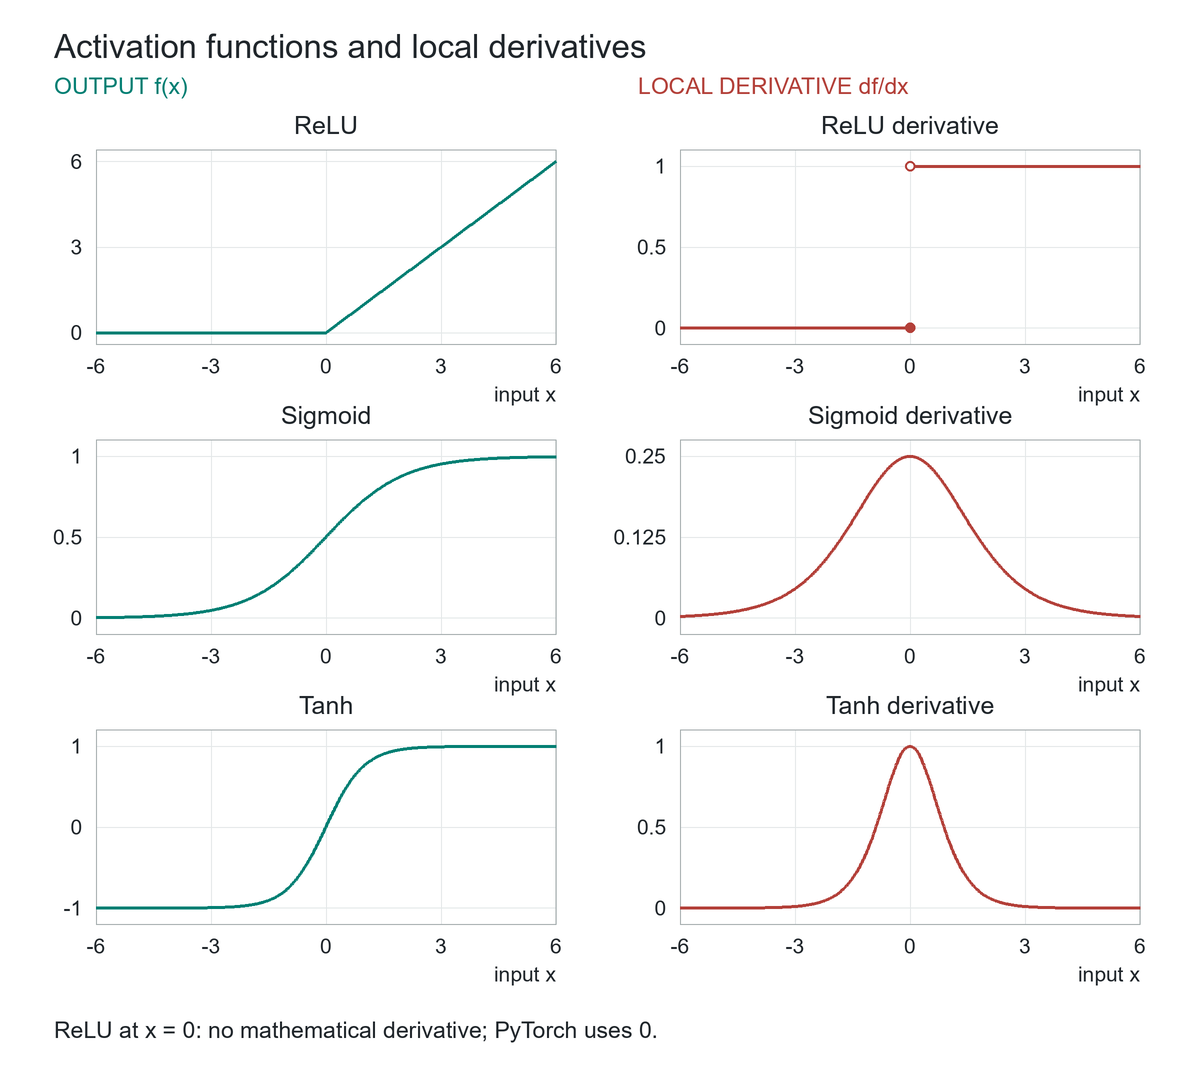

Sigmoid和Tanh在输入绝对值很大时, 输出越来越平, 导数接近0. 这叫**饱和 (Saturation)**. 反向传播中连续乘上很小的导数, 可能让前面的参数得到的梯度非常小, 这就是**梯度消失 (Vanishing Gradients)** 的一种来源, 后面会系统学习.

Sigmoid的数值虽然在`(0, 1)`, 但**隐藏层输出并不会因此自动具有类别概率的含义**, 也不要求一行加起来等于1.
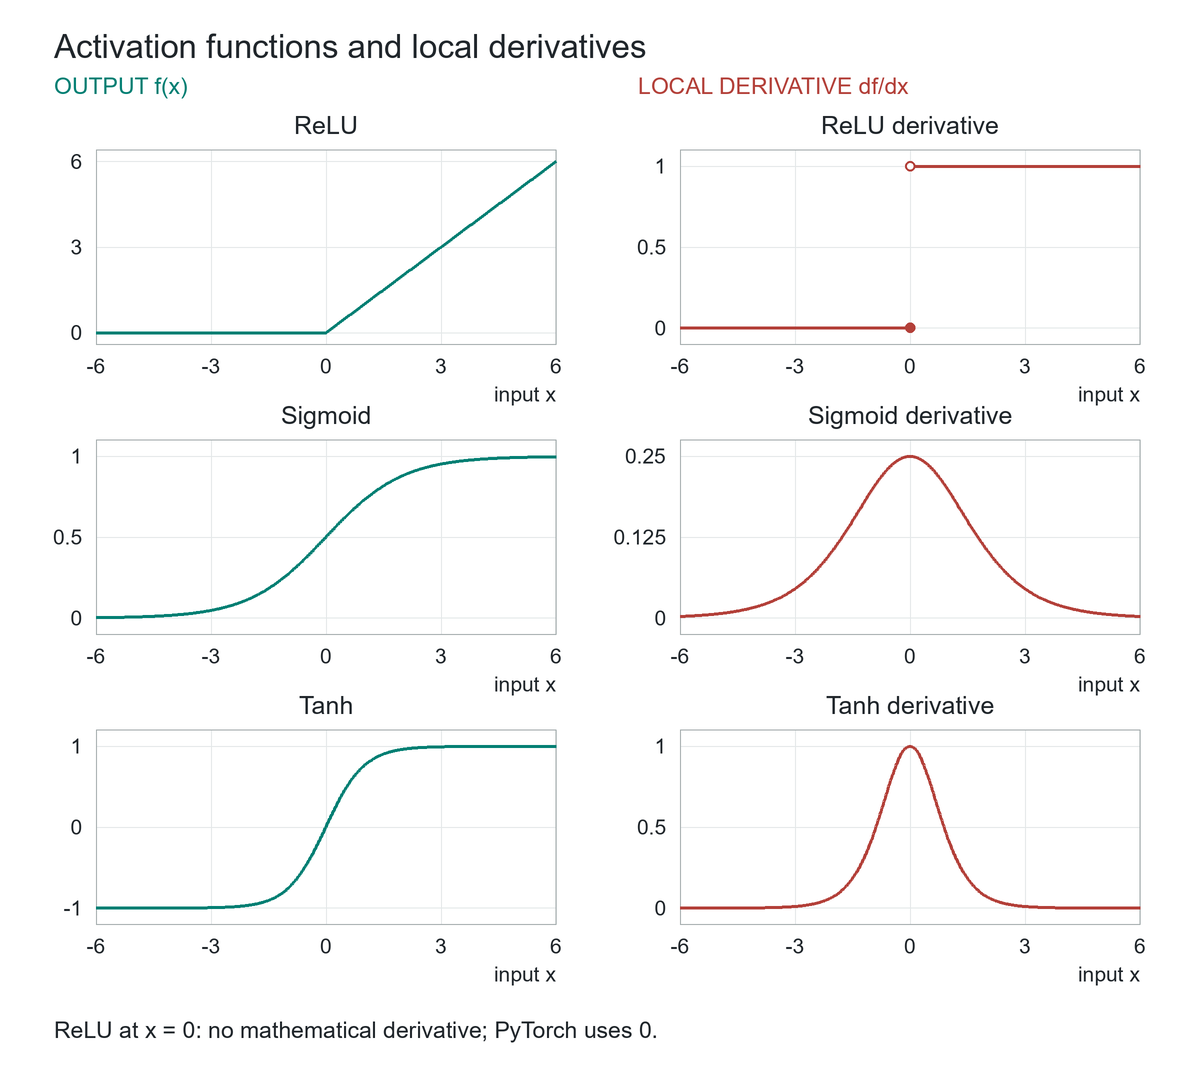
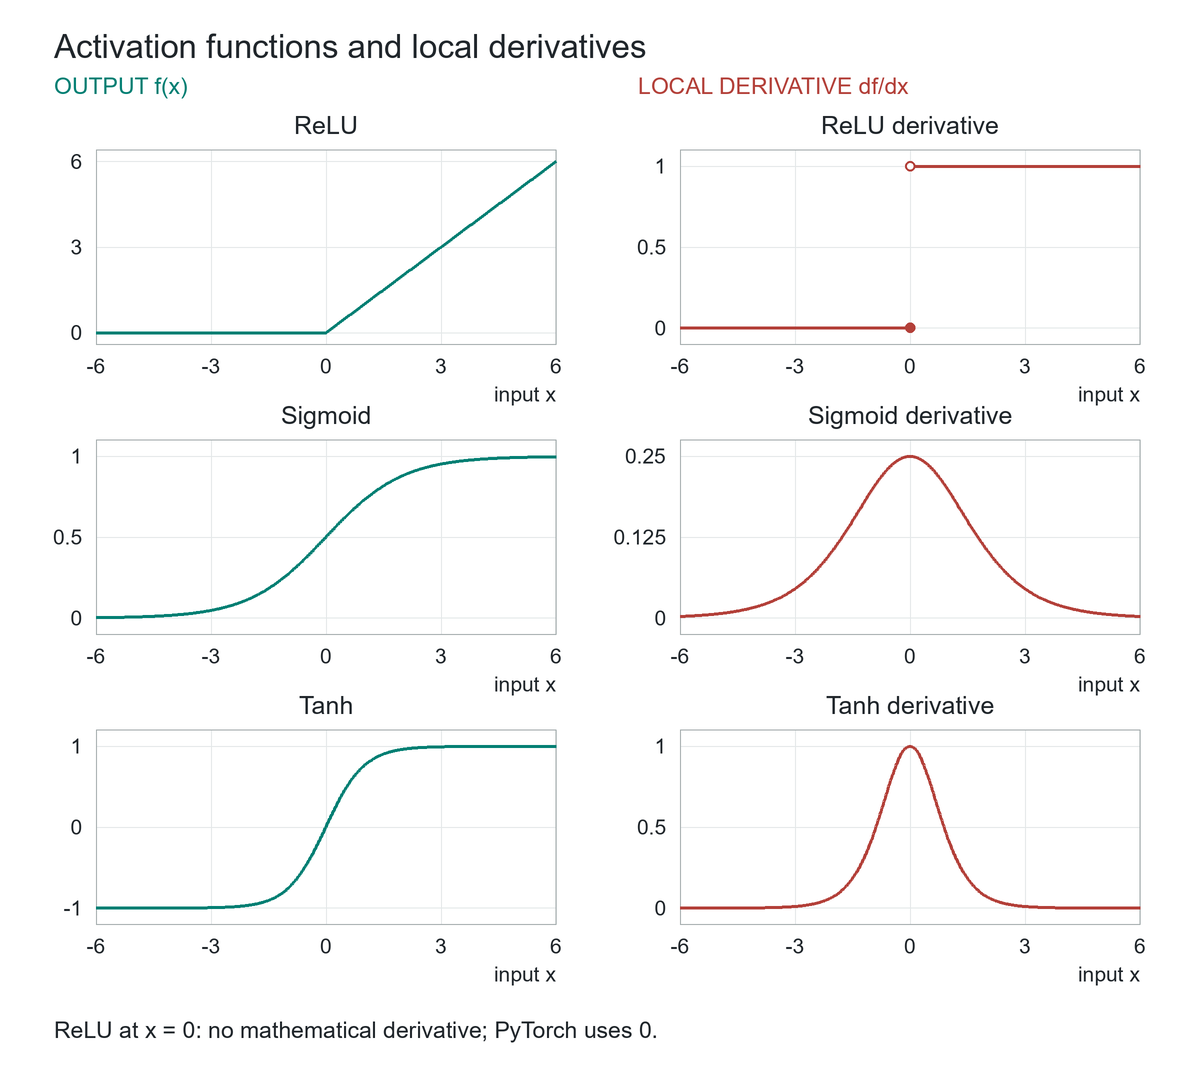

#### 4. 放回我们的项目

本项目先用`Linear -> ReLU -> Linear -> 原始logits`. ReLU简单, 正数区域的局部导数为1, 但它也不是所有任务的唯一最佳选择.

ReLU, Sigmoid, Tanh本身都没有可训练参数, 逐元素应用时不改变形状. 教材还介绍了**PReLU (Parameterized ReLU, 参数化ReLU)**: 正数保持鸳鸯, 负数变成$\alpha$*x, 其中斜率$\alpha$可以学习; 负数区域对输入的导数就是$\alpha$.

教材的**通用近似定理 (Universal Approximation Theorem)** 可以先理解为: 在适当激活函数, 足够多隐藏单元等条件下, 单隐藏层网络能在指定的封闭有界输入范围内, 把连续函数近似得任意准确. 连续是指输入微小变化不会造成输出突然跳变.

但**存在合适函数, 不等于训练一定找得到; 表达能力更强, 也不等于验证效果一定更好**.

---
## 多层模型怎样获得参数

#### 1. 先完成前向计算

**前向传播 (Forward Propagation)** 就是按以来顺序, 从输入算到输出和损失; **计算图 (Computational Graph)** 记录这些计算之间的依赖关系.

用一个`1 -> 2 -> 1`的小网络: 一个输入特征, 两个隐藏单元, 一个输出. 输入`x=2`, 真实值`y=5`, 当前参数使它进行以下计算:
```
第一层：z1 = 1*x + 1       z2 = -1*x + 1
激活后：h1 = ReLU(z1)     h2 = ReLU(z2)
第二层：o = 2*h1 - 3*h2 + 1
损失：  L = (o-y)**2 / 2
```

这里的乘法系数和偏置都是可训练参数的当前值. 暂用半平方损失方便手算, **分类项目仍然使用交叉熵**.

依次得到:
- `z = [3, -1]`
- `h = [3, 0]`
- 预测值`o = 7`
- 损失`L = 2`


#### 2. 梯度怎样传回来

**反向传播 (Backpropagation)** 从损失出发, 沿计算图反向应用链式法则, 计算损失对中间变量和参数的梯度.

先从最后一步开始:
$$\frac {\partial L}{\partial o} = o - y = 2$$

由于`o = 2*h1 - 3*h2 + 1`, 传到两个隐藏输出的梯度分别是:
$$\frac {\partial L}{\partial h} = [2\times 2, 2\times(-3)] = [4, -6]$$

再经过ReLU. `z=[3, -1]`对应的局部导数使`[1, 0]`, 逐元素相乘:
$$\frac {\partial L}{\partial z} = [4, -6]\odot[1, 0] = [4, 0]$$

这里的$\odot$表示逐元素乘法. 注意: `h2`的梯度是`-6`, 但经过ReLU后, 传回`z2`的梯度变成了`0`.

#### 3. 两层参数各自得到什么

记第一层参数为`W1, b1`, 第二层参数为`W2, b2`. 因为"输入乘权重"对权重求导得到输入, 所以:
| 参数 | 梯度计算 | 梯度结果及形状 |
|---|---|---|
| `W2` | 隐藏输出乘上传回来的梯度 | `[[6.], [0.]]`，形状 `(2,1)` |
| `b2` | 加偏置的局部导数为 1 | `[2.]`，形状 `(1,)` |
| `W1` | 输入 `2` 乘上 `[4,0]` | `[[8.,0.]]`，形状 `(1,2)` |
| `b1` | 加偏置的局部导数为 1 | `[4.,0.]`，形状 `(2,)` |

**每个参数的梯度形状, 都与该参数相同**. 反向传播是在计算这些梯度, 参数更新仍由之后的`optimizer.step()`完成.

多条样本共用一套参数, 因此各条样本对同一参数的梯度贡献需要汇总; 如果损失取平均, 平均系数也会自动通过链式法则传回来, 不能再重复除一次batch size.

#### 4. 为什么需要中间结果

例如, 计算`W2`的梯度时需要刚才的隐藏输出`h`; ReLU的反向计算也需要知道哪些位置处于正数区域. 因此, Autograd会按运算需要保存一些前向结果, 共反向计算使用.

这也是训练通常比纯推理占用更多内存的原因之一: batch更大, 隐藏层更宽或更深, 通常会产生更多中间数据.

**保存前向结果, 不等于是默认保留中间张量的`.grad`**. `z`, `h`的梯度可以被计算和使用, 而它们的`.grad`默认仍是`None`; 需要查看时, 在反向传播前调用`.retain_grad()`.

教材额外加入的正则化项, 也就是"在损失上增加一项来约束参数大小", 之后详细讲.

#### 5. 用PyTorch核对

In [32]:
import torch

X = torch.tensor([[2.]])
target = torch.tensor([[5.]])
W1 = torch.tensor([[1., -1.]], requires_grad=True)
b1 = torch.tensor([1., 1.], requires_grad=True)
W2 = torch.tensor([[2.], [-3.]], requires_grad=True)
b2 = torch.tensor([1.], requires_grad=True)

Z = X @ W1 + b1 # 第一层线性计算
H = torch.relu(Z) # ReLU
out = H @ W2 + b2 # 第二层线性计算
loss = ((out - target) ** 2).mean() / 2 # 平均半平方损失

Z.retain_grad()
H.retain_grad()
loss.backward()

print("out / loss:", out.item(), loss.item())
print("H.grad / Z.grad:", H.grad, Z.grad)
for name, parameter in [("W1", W1), ("b1", b1), ("W2", W2), ("b2", b2)]:
    print(name, parameter.grad, parameter.grad.shape)

out / loss: 7.0 2.0
H.grad / Z.grad: tensor([[ 4., -6.]]) tensor([[4., 0.]])
W1 tensor([[8., 0.]]) torch.Size([1, 2])
b1 tensor([4., 0.]) torch.Size([2])
W2 tensor([[6.],
        [0.]]) torch.Size([2, 1])
b2 tensor([2.]) torch.Size([1])


---
## 从零实现MLP分类器: 数据准备和初始化

#### 1. 准备数据

In [33]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import FashionMNIST
from torchvision.transforms import ToTensor

DATA_ROOT = (
    "../Unit2_Datasets_and_DataLoaders/data"
)
full_train = FashionMNIST(
    DATA_ROOT, train=True, transform=ToTensor(), download=False,
)
train_dataset, val_dataset = random_split(
    full_train, [50000, 10000],
    generator=torch.Generator().manual_seed(42),
)
batch_size = 128
mlp_train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True,
    generator=torch.Generator().manual_seed(123),
)
mlp_train_eval_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
mlp_val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

X_check, y_check = next(iter(mlp_val_loader))
print("samples:", len(train_dataset), len(val_dataset))
print("batch:", X_check.shape, y_check.shape)
assert not (set(train_dataset.indices) & set(val_dataset.indices))

samples: 50000 10000
batch: torch.Size([128, 1, 28, 28]) torch.Size([128])


#### 2. 参数从哪里开始

**初始化 (Initialization)** 就是在训练开始前, 给参数设定初始值. 我们采用`784 -> 256 -> 10`, 需要两组权重, 两组偏置.

权重用均值为0, 标准差为`0.01`的随机数; 偏置首先设为0. 随即权重让不同隐藏单元有不同起点, 更深入的初始化原理稍后展开.

例如, 下面创建一个形状为`(3, 4)`的随机叶子参数:
```
example_W = (torch.randn(3, 4) * 0.01).requires_grad_()
```

注意顺序: **先生成并缩放数值, 再开启梯度记录**. 若先开启梯度再做乘法, 乘法结果就不是叶子张量了. 我们本轮让四组参数都保持`requires_grad=True, is_leaf=True`.

偏置可以用`torch.zeros(长度, requires_grad=True)`创建. 教材采用`nn.Parameter`是表示模型可训练参数的特殊Tensor类型; 这里先使用普通叶子Tensor, 后面再结合`nn.Module`讲参数管理.

#### 3. 代码

下面使用`mlp_`前缀, 与之前小实验的`W1, b1`等变量分开. 参数初始化放在独立单元, 之后不要再每个batch内重复执行.

In [34]:
torch.manual_seed(42)
num_inputs, num_hiddens, num_outputs = 784, 256, 10

mlp_W1 = (torch.randn(num_inputs, num_hiddens) * 0.01).requires_grad_() # 随机小权重，形状 (784, 256)
mlp_b1 = torch.zeros([256, ], requires_grad=True) # 全零偏置，形状 (256,)
mlp_W2 = (torch.randn(num_hiddens, num_outputs) * 0.01).requires_grad_() # 随机小权重，形状 (256, 10)
mlp_b2 = torch.zeros([10, ], requires_grad=True) # 全零偏置，形状 (10,)

mlp_params = [mlp_W1, mlp_b1, mlp_W2, mlp_b2]
for name, parameter in zip(["W1", "b1", "W2", "b2"], mlp_params):
    print(name, tuple(parameter.shape), parameter.requires_grad,
          parameter.is_leaf, parameter.grad)
    assert parameter.requires_grad and parameter.is_leaf

print("parameter count:", sum(p.numel() for p in mlp_params))

W1 (784, 256) True True None
b1 (256,) True True None
W2 (256, 10) True True None
b2 (10,) True True None
parameter count: 203530


---
## 从零实现MLP分类器: 手写ReLU与完整前向计算

#### 1. 用逐元素选择实现ReLU

我们要实现的规则是: **输入大于0是保留输入, 否则输出0**.

这里用一个新工具: `torch.where(condition, a, b)`. 它逐个位置检查条件: `True`取`a`对应位置的值, `False`取`b`.

例如, 输入是`[-2, 0, 3]`:
- `输入>0`得到`[False, False, True]`, 这种用于选择位置的布尔张量叫**掩码 (Mask)**.
- 条件为真时取原值, 否则取零, 就得到`[0, 0, 3]`.
- `torch.zeros_like(Z)`可以生成与`Z`形状, 数据类型, 设备相同的全零张量.

教材有一个需要补充的细节: 它用`torch.max(Z, zeros)`实现ReLU, 前向值相同, 但两个Tensor的最大值算子在相等处会分配梯度, 零点处对`Z`的梯度为`0.5`, 与`torch.relu`采用的`0`不同. 我们用严格的`Z > 0`条件选择, 让零点走常数零分支, 保持之前学过的约定. 知道这个区别即可, 不需要展开不可导点的数学证明.

小检查:

In [35]:
def manual_relu(Z):
    return torch.where(Z > 0, Z, 0)  # 条件、条件为真时的值、否则的值

probe = torch.tensor([-2., 0., 3.], requires_grad=True)
probe_out = manual_relu(probe)
probe_out.sum().backward()

print("output:", probe_out.detach())
print("gradient:", probe.grad)
assert torch.equal(probe_out.detach(), torch.relu(probe.detach()))
assert torch.equal(probe.grad, torch.tensor([0., 0., 1.]))

output: tensor([0., 0., 3.])
gradient: tensor([0., 0., 1.])


#### 2. 把两层计算接起来

沿用已经初始化好的四组`mlp_`参数, 前向过程是:
$$Z = X_{flat}W_1 + b_1, \;\;\;\; H = ReLU(Z), \;\;\;\; logits = HW_2 + b_2$$

| 阶段 | 形状 |
|---|---|
| 原始图片 `X` | `(B,1,28,28)` |
| 展平后的 `X_flat` | `(B,784)` |
| 第一层结果 `Z` | `(B,256)` |
| 激活后的 `H` | `(B,256)` |
| 输出 `logits` | `(B,10)` |

第一层把像素组合成隐藏特征; ReLU对这些结果逐元素变换; 第二层再把隐藏特征组合成类别分数.

**最后输出的是原始logits, 可以为正或负, 不要求一行加起来等于1. 本项目这里不再加ReLU或Softmax**.



In [36]:
def manual_mlp(X):
    X_flat = torch.flatten(X, start_dim=1) # 保留第 0 个样本轴，展平剩余轴
    Z = X_flat @ mlp_W1 + mlp_b1 # 使用 mlp_W1、mlp_b1
    H = manual_relu(Z)
    logits = H @ mlp_W2 + mlp_b2 # 使用 mlp_W2、mlp_b2
    return logits

logits_check = manual_mlp(X_check)
print("input:", X_check.shape)
print("logits:", logits_check.shape)
print("requires_grad:", logits_check.requires_grad)

assert logits_check.shape == (X_check.shape[0], num_outputs)
assert torch.isfinite(logits_check).all()
assert logits_check.requires_grad
assert all(p.grad is None for p in mlp_params)

input: torch.Size([128, 1, 28, 28])
logits: torch.Size([128, 10])
requires_grad: True


---
## 从零实现MLP分类器: 走通一个batch的训练

#### 1. 这次要接上什么

我们已经有`manual_mlp`, 现在把它放进熟悉的训练顺序:
```
清除旧梯度 → 前向预测 → 平均交叉熵 → 反向传播 → SGD 更新
```

这里有三个要点:
- 使用`mlp_train_loader`中的数据, 不使用来自验证集的`X_check, y_check`.
- `CrossEntropyLoss(reduction="mean")`已经求平均, **不再除以batch size, 也不除以2**.
- 新优化器接收`mlp_params`, 包含两层的权重和偏置. 当前SGD配置下, 每个参数按原值减去`0.1 × 梯度`更新

我们会保存一份参数的独立副本: 检查**`backward()`之后参数没变, `step()`之后参数才变**. `detach().clone()`用来创建这个不参与求导, 也不与原参数共用数据的副本.

#### 2. 补全训练代码

In [37]:
from torch import nn

names = ["W1", "b1", "W2", "b2"]
loss_fn = nn.CrossEntropyLoss(reduction="mean")
mlp_optimizer = torch.optim.SGD(mlp_params, lr=0.1) # SGD，参数为 mlp_params，学习率 0.1

X_batch, y_batch = next(iter(mlp_train_loader))
before_step = [p.detach().clone() for p in mlp_params]

mlp_optimizer.zero_grad() # 清除旧梯度
logits_batch = manual_mlp(X_batch) # 调用手写 MLP
loss = loss_fn(logits_batch, y_batch) # 用 logits_batch 和 y_batch 计算损失

assert logits_batch.shape == (y_batch.shape[0], num_outputs)
assert y_batch.dtype == torch.long
assert loss.ndim == 0
assert torch.isfinite(loss)
before_loss = loss.item()

loss.backward() # 反向传播

for name, p in zip(names, mlp_params):
    assert p.grad is not None
    assert p.grad.shape == p.shape
    assert torch.isfinite(p.grad).all()
    print(name, "gradient shape:", tuple(p.grad.shape),
          "max |gradient|:", p.grad.abs().max().item())

assert all(
    torch.equal(p.detach(), old)
    for p, old in zip(mlp_params, before_step)
)

mlp_optimizer.step() # 优化器更新参数

changes = [
    (p.detach() - old).abs().max().item()
    for p, old in zip(mlp_params, before_step)
]
assert any(change > 0 for change in changes)

with torch.no_grad():
    after_loss = loss_fn(manual_mlp(X_batch), y_batch).item()

print("loss before / after:", before_loss, after_loss)
print("max parameter changes:", dict(zip(names, changes)))

W1 gradient shape: (784, 256) max |gradient|: 0.005299968179315329
b1 gradient shape: (256,) max |gradient|: 0.004688032902777195
W2 gradient shape: (256, 10) max |gradient|: 0.033868953585624695
b2 gradient shape: (10,) max |gradient|: 0.055856626480817795
loss before / after: 2.302316427230835 2.2909951210021973
max parameter changes: {'W1': 0.0005299968179315329, 'b1': 0.00046880330774001777, 'W2': 0.003386895637959242, 'b2': 0.005585662554949522}


#### 3. 怎样看结果

`max |gradient|`是这组参数中梯度绝对值的最大值; `max parameter changes`是其中最大的参数变化幅度, 方便检查而不打印整个矩阵.

部分梯度元素为零可以是正常的, **不要求每个参数元素都发生变化**. 更新前后同一批的损失用于观察, 也不把"一次更新必然降低损失"设为绝对断言.

每运行一次这个单元, 就会再更新一次参数. 下一小步正式训练前, 我们会重新初始化参数, 优化器和训练数据顺序. 本步结束后参数已有梯度, 之前"所有`.grad`都是`None`"的断言便不再适用于训练后的状态.

---
## 从零实现MLP分类器: 完整训练, 验证与结果分析.

#### 1. 重置正式起点

保留原来的数据划分和前向函数, 重新创建参数, 参数列表, 优化器和训练加载器.

`mlp_initial_params`保存训练前的独立副本, 之后可用于框架版对照.

In [38]:
from torch import nn
torch.manual_seed(42)
num_inputs, num_hiddens, num_outputs = 784, 256, 10
mlp_W1 = (torch.randn(num_inputs, num_hiddens) * 0.01).requires_grad_()
mlp_b1 = torch.zeros(num_hiddens, requires_grad=True)
mlp_W2 = (torch.randn(num_hiddens, num_outputs) * 0.01).requires_grad_()
mlp_b2 = torch.zeros(num_outputs, requires_grad=True)
mlp_params = [mlp_W1, mlp_b1, mlp_W2, mlp_b2]
mlp_initial_params = [p.detach().clone() for p in mlp_params]
mlp_train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True,
    generator=torch.Generator().manual_seed(123),
)
loss_fn = nn.CrossEntropyLoss(reduction="mean")
mlp_optimizer = torch.optim.SGD(mlp_params, lr=0.1)

#### 2. 准备评估函数

沿用我们之前的评估方法: 固定当前参数, 重新遍历指定数据集, 不执行反向传播或更新. 损失按样本数汇总, 避免最后一小批与完整批次占相同权重. 当前模型是普通函数, 不调用`.eval()`

In [39]:
def evaluate_mlp(loader):
    loss_sum, correct_sum, sample_count = 0.0, 0, 0
    with torch.no_grad():
        for X, y in loader:
            logits = manual_mlp(X)
            n = y.numel()
            loss_sum += loss_fn(logits, y).item() * n
            correct_sum += (logits.argmax(dim=1) == y).sum().item()
            sample_count += n
    return loss_sum / sample_count, correct_sum / sample_count

#### 3. 完成循环

外层遍历epoch, 内层遍历训练batch. 每轮结束后, 用该轮最终参数分别计算训练集和验证集指标. 每条`mlp_history`记录依次为: `训练损失, 训练准确率, 验证损失, 验证准确率`.

In [40]:
print("before:", evaluate_mlp(mlp_train_eval_loader), evaluate_mlp(mlp_val_loader))
mlp_history = []

for epoch in range(10):
    for X_batch, y_batch in mlp_train_loader:
        mlp_optimizer.zero_grad() # 清除旧梯度
        logits = manual_mlp(X_batch) # 手写 MLP 前向计算
        loss = loss_fn(logits, y_batch) # 平均交叉熵
        loss.backward() # 反向传播
        mlp_optimizer.step() # 更新参数

    train_loss, train_acc = evaluate_mlp(mlp_train_eval_loader)
    val_loss, val_acc = evaluate_mlp(mlp_val_loader)
    mlp_history.append((train_loss, train_acc, val_loss, val_acc))
    print(
        f"epoch {epoch + 1:02d}: "
        f"train loss {train_loss:.4f}, acc {train_acc:.1%}; "
        f"val loss {val_loss:.4f}, acc {val_acc:.1%}"
    )

assert len(mlp_history) == 10
assert any(
    not torch.equal(p.detach(), p0)
    for p, p0 in zip(mlp_params, mlp_initial_params)
)

before: (2.3023422235107422, 0.10418) (2.3026619117736815, 0.0986)
epoch 01: train loss 0.5728, acc 80.3%; val loss 0.5848, acc 80.0%
epoch 02: train loss 0.4854, acc 82.7%; val loss 0.4998, acc 82.2%
epoch 03: train loss 0.4450, acc 84.3%; val loss 0.4671, acc 83.3%
epoch 04: train loss 0.4031, acc 86.0%; val loss 0.4222, acc 85.3%
epoch 05: train loss 0.4135, acc 85.2%; val loss 0.4310, acc 84.7%
epoch 06: train loss 0.3871, acc 86.2%; val loss 0.4075, acc 85.3%
epoch 07: train loss 0.3593, acc 87.2%; val loss 0.3823, acc 86.3%
epoch 08: train loss 0.3590, acc 87.1%; val loss 0.3816, acc 86.5%
epoch 09: train loss 0.3522, acc 87.4%; val loss 0.3864, acc 86.1%
epoch 10: train loss 0.3390, acc 87.8%; val loss 0.3697, acc 86.6%


#### 4. 画学习曲线

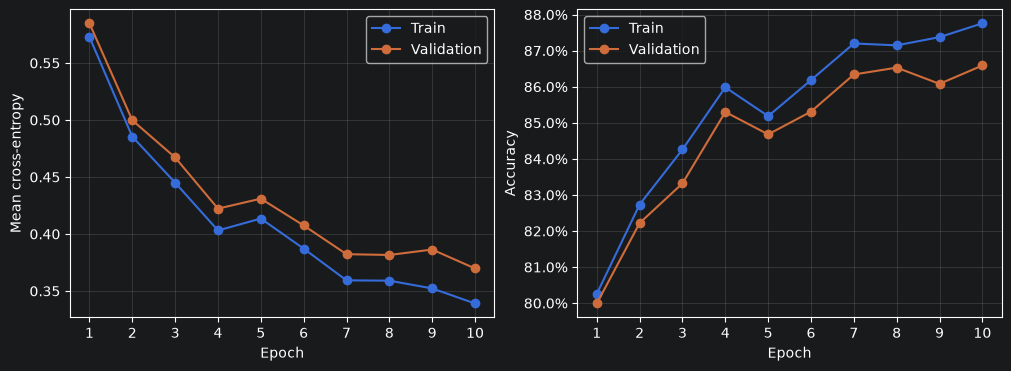

In [41]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

epochs = range(1, len(mlp_history) + 1)
train_losses, train_accs, val_losses, val_accs = zip(*mlp_history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for ax, train_values, val_values, ylabel in [
    (axes[0], train_losses, val_losses, "Mean cross-entropy"),
    (axes[1], train_accs, val_accs, "Accuracy"),
]:
    ax.plot(epochs, train_values, marker="o", label="Train")
    ax.plot(epochs, val_values, marker="o", label="Validation")
    ax.set(xlabel="Epoch", ylabel=ylabel)
    ax.set_xticks(epochs)
    ax.grid(alpha=0.25)
    ax.legend()
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

#### 5. 查看预测与错分

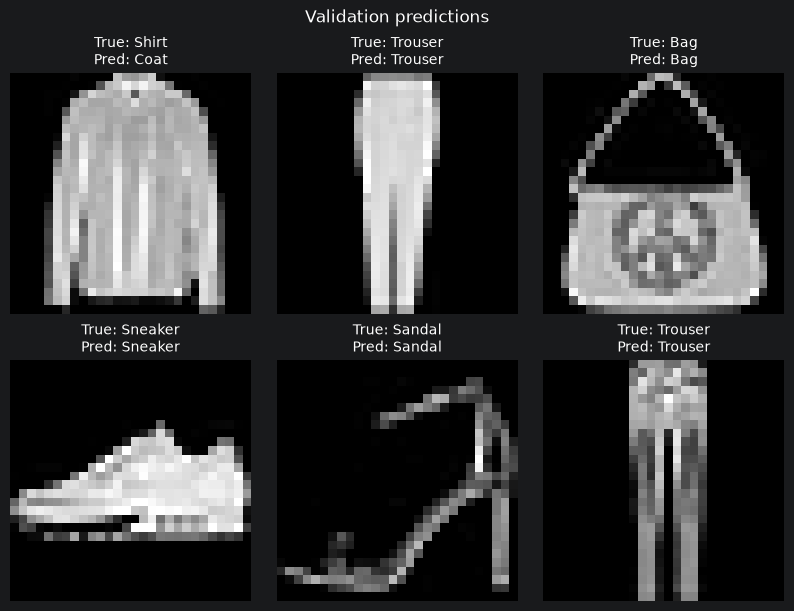

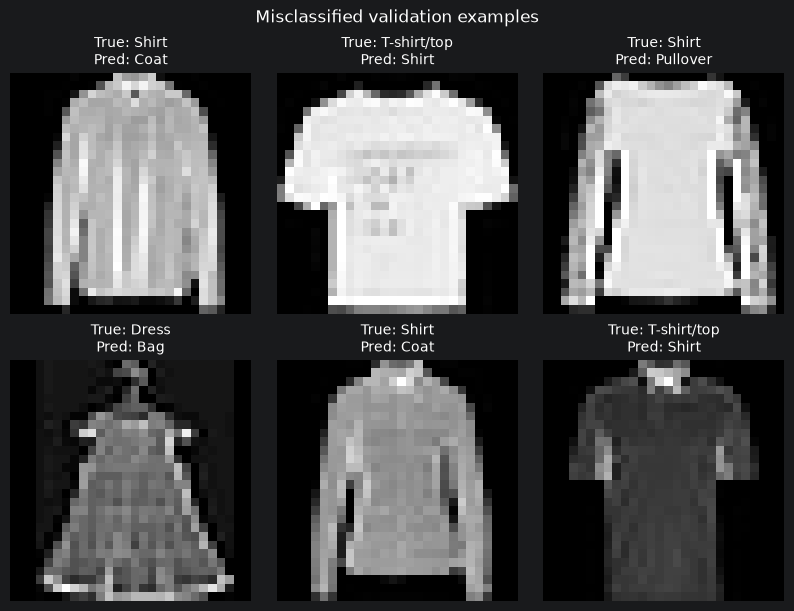

In [42]:
X_vis, y_vis = next(iter(mlp_val_loader))
with torch.no_grad():
    pred_vis = manual_mlp(X_vis).argmax(dim=1)
classes = full_train.classes

def show_mlp_examples(indices, title):
    if not indices:
        print("No matching samples in this batch.")
        return
    fig, axes = plt.subplots(2, 3, figsize=(8, 6), constrained_layout=True)
    fig.suptitle(title)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, indices[:6]):
        ax.imshow(X_vis[i, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(
            f"True: {classes[y_vis[i].item()]}\n"
            f"Pred: {classes[pred_vis[i].item()]}",
            fontsize=10,
        )
    plt.show()

show_mlp_examples(list(range(min(6, len(y_vis)))), "Validation predictions")
wrong_indices = (pred_vis != y_vis).nonzero(as_tuple=True)[0].tolist()
show_mlp_examples(wrong_indices, "Misclassified validation examples")

---
## 用`nn.Module`组织MLP: 把手写MLP组织成模型类

#### 1. 先把它与已经写好的代码对应起来

我们的手写MLP做的是:
```
X_flat = torch.flatten(X, start_dim=1)
Z = X_flat @ mlp_W1 + mlp_b1
H = manual_relu(Z)
logits = H @ mlp_W2 + mlp_b2
```

框架版仍然做这四件事, 对应关系是:
| 手写操作 | 框架中的模块 |
|---|---|
| 展平每张图片，保留 batch 轴 | `nn.Flatten()` |
| 第一层矩阵乘法加偏置 | `nn.Linear(784, 256)` |
| ReLU 激活 | `nn.ReLU()` |
| 第二层矩阵乘法加偏置 | `nn.Linear(256, 10)` |

**模块 (module)** 可以理解为一个接收输入, 产生输出的计算单元. 它可以带参数, 也可以不带参数: `Linear`带权重和偏置, `ReLU`和`Flatten`不带可训练参数.

我们熟悉的`nn.Sequential`就是把这些模块按顺序连接起来:
```
net = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 10),
)
```

接下来, 模型类让我们自己明确写出这个计算程序.

#### 2. 先理解几个Python词, 再看代码

| 名词或写法 | 大白话解释 |
|---|---|
| 类（class） | 描述一种对象应该包含什么、能做什么的定义 |
| 实例（instance） | 根据这个类创建出来的具体对象，例如某一个模型 |
| 属性（attribute） | 对象保存的东西，例如 `model.fc1` |
| 方法（method） | 属于这个对象的函数，例如 `forward` |
| `self` | 当前这个对象自己 |
| 继承（inheritance） | 在已有类的能力上，定义自己的类 |

例如, `MiniMLP`可以是模型的定义, `model_a = MiniMLP()`则创建了一个具体模型. 这些是Python类与实例的基本含义.

#### 3. 看一个小网络: **3个输入特征 -> 4个隐藏单元 -> 2个类别分数**

In [43]:
from torch import nn

class MiniMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(3, 4)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(4, 2)

    def forward(self, X):
        Z = self.fc1(X)
        H = self.relu(Z)
        logits = self.fc2(H)
        return logits

我们逐段拆开.

`class MiniMLP(nn.Module):`表示: 定义一个叫`MiniMLP`的类, 让它继承PyTorch的`nn.Module`. `nn.Module`是构建模型的基础, 提供统一管理模型的能力.

`def __init__(self):`中的`__init__`是初始化方法. 创建模型实例时, Python会自动调用它:
```
model_a = MiniMLP()
```

于是, `model_a`创建并保存了自己的第一层, ReLU和第二层. 创建层时, `nn.Linear`也会创建并初始化权重与偏置.

`super().__init__()`则先调用父类的初始化方法. 在这里, 父类就是`nn.Module`. 它会准备管理子模块和参数所需的内部结构, 因此要放在给`self`添加这些层之前.

`self.fc1 = nn.Linear(3, 4)`可以读成: 给当前这个模型保存一个名叫`fc1`的层, 它把3个特征变成4个特征.

**`fc`是fully connected, 全连接**常见的缩写. `fc1`, `fc2`是我们自己取的名字.

这里写`self.fc1`, 是为了让这个层属于模型, 并在之后调用模型时继续使用. `forward`中的`Z`, `H`则是本次计算产生的中间结果.

`__init__`负责创建和保存层, `forward`负责使用这些层计算.

假设:
```
X = torch.randn(8, 3)
logits = model_a(X)
```

这次计算的形状是:
```
X           Z          H         logits
(8, 3)  →  (8, 4)  →  (8, 4)  →  (8, 2)
```

调用`model_a(X)`时, 会使用已经保存的`fc1`, `fc2`, 不会重新调用`__init__`, 因此也不会每次预测都重新随机初始化参数.

这里还要区分:
```
model_a = MiniMLP()  # 创建一个模型
model_b = MiniMLP()  # 再创建一个模型
```

按照上面这个类的写法, 两者结构相同, 各自拥有自己的参数.

#### 4. 为什么定义的是`forward`, 使用时却写`model_a(X)`?

因为`nn.Model`提供了统一的调用入口. `model_a(X)`会通过这个入口执行我们写的`forward`, 同时处理框架等级的其他调用行为.

因此, 正常使用模型时写:
```
logits = model_a(X)
```

直接调用`model_a.forward(X)`通常也能算出结果, 记录梯度, 但会绕过统一入口中的部分处理, 所以我们沿用官方推荐的`model_a(X)`.

#### 5. 现在把Fashion-MNIST的模型写出来



In [44]:
import torch
from torch import nn

class FashionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten(start_dim=1) # TODO：保留 batch 轴，展平每张图片
        self.fc1 = nn.Linear(784, 256) # TODO：784 → 256
        self.relu = nn.ReLU() # TODO：ReLU
        self.fc2 = nn.Linear(256, 10) # TODO：256 → 10

    def forward(self, X):
        X_flat = self.flatten(X) # TODO：调用模型保存的展平模块
        Z = self.fc1(X_flat) # TODO：调用第一层
        H = self.relu(Z) # TODO：调用 ReLU
        logits = self.fc2(H) # TODO：调用第二层
        return logits

framework_mlp = FashionMLP()

X_probe = torch.zeros(4, 1, 28, 28)
logits_probe = framework_mlp(X_probe)

print(framework_mlp)
print("输出形状：", logits_probe.shape)

assert logits_probe.shape == (4, 10)

FashionMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)
输出形状： torch.Size([4, 10])


---
## 用`nn.Module`组织MLP: 参数和设备如何统一管理

我们以前需要自己维护:
```
mlp_params = [mlp_W1, mlp_b1, mlp_W2, mlp_b2]
```

现在可以使用:
```
framework_mlp.parameters()
```

为什么模型知道去哪里找这些参数? 这里需要认识**参数注册 (parameter registration)**: 把一个Tensor登记为模型的参数, 让模型可以统一找到和管理它.

当我们写:
```
self.fc1 = nn.Linear(784, 256)
```

`fc1`会成为模型保存的**子模块 (submodule)**, 也就是模型内部的一个模块. 它的权重与偏置本来就是`nn.Parameter`, 所以模型能够找到它们. 第二层同理.

#### **`parameters()`和`named_parameters()`的区别很直接**

| 方法 | 遍历时获得什么 |
|---|---|
| `parameters()` | 参数本身 |
| `named_parameters()` | 参数名称，以及参数本身 |

对我们的模型, 应该找到:
| 名称 | 形状 | 元素数量 |
|---|---|---:|
| `fc1.weight` | `(256, 784)` | 200704 |
| `fc1.bias` | `(256,)` | 256 |
| `fc2.weight` | `(10, 256)` | 2560 |
| `fc2.bias` | `(10,)` | 10 |

因此, 模型有**4个参数张量, 共203530个参数元素**. `Flatten`和`ReLU`没有可训练参数.

运行下面检查:


In [45]:
for name, p in framework_mlp.named_parameters():
    print(
        name,
        "shape:", tuple(p.shape),
        "requires_grad:", p.requires_grad,
        "device:", p.device,
    )

print(
    "参数元素总数:",
    sum(p.numel() for p in framework_mlp.parameters()),
)

fc1.weight shape: (256, 784) requires_grad: True device: cpu
fc1.bias shape: (256,) requires_grad: True device: cpu
fc2.weight shape: (10, 256) requires_grad: True device: cpu
fc2.bias shape: (10,) requires_grad: True device: cpu
参数元素总数: 203530


这些方法是在访问已有参数, **不会复制参数或重新初始化**. 以后把`model.parameters()`交给优化器, 就能让优化器管理这些参数.

#### **接下来区分`nn.Parameter`与普通Tensor**

`nn.Parameter`是一种特殊的Tensor: 把它赋给模型属性时, 它会自动注册为模型参数. 普通Tensor即使设置了`requires_grad=True`, 也没有这个自动注册效果.

假设再一个模型的`__init__`里写:
```
self.a = torch.ones(3, requires_grad=True)
self.b = nn.Parameter(torch.ones(3))
```

两者的区别是:
| 属性 | 能否参与自动求导 | 是否自动出现在 `model.parameters()` 中 |
|---|---|---|
| `self.a` | 能，前提是参与相关计算 | 否 |
| `self.b` | 能，默认 `requires_grad=True` | 是 |

所以要分清三件事:
- `requires_grad`: 是否需要追踪相关运算来求梯度.
- **参数注册**: 模型是否把它登记为自己的参数.
- **优化器更新**: 优化器是否拿到了它, 并在`step()`时依据梯度更新它.

我们之前的手写Tensor没有注册, 但我们把它们明确放进`mlp_params`交给优化器, 因此照样能训练.

另外, 注册过的参数即使后来设成`requires_grad=False`, 仍然会出现在`parameters()`中.

#### **最后, 把模型与数据放到相同设备**.

`device`表示Tensor所在的计算设备, 例如CPU或通过CUDA使用的GPU. 我们已经接触过它, 现在模型可以统一迁移内部参数:
```
model = model.to(device)
```

但**移动模型不会自动移动输入数据**. 输入也要放到相应设备; 训练时参与损失计算的标签同样需要处理.

用下面这个临时模型做一次设备检查, 不影响已有的`framework_mlp`:

In [46]:
practice_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

device_demo_model = FashionMLP().to(practice_device)

device_demo_X = torch.zeros(4, 1, 28, 28)
device_demo_X = device_demo_X.to(practice_device)

with torch.no_grad():
    device_demo_logits = device_demo_model(device_demo_X)

print("参数设备:", device_demo_model.fc1.weight.device)
print("输入设备:", device_demo_X.device)
print("输出设备:", device_demo_logits.device)
print("输出形状:", device_demo_logits.shape)

参数设备: cpu
输入设备: cpu
输出设备: cpu
输出形状: torch.Size([4, 10])


这里注意: 普通Tensor的`.to(...)`要使用它返回的Tensor, 所以写成`device_demo_X = device_demo_X.to(...)`.

正式训练时, 我们采用这个顺序:
```
创建模型 → 放到目标设备 → 创建优化器 → 开始训练
```

---
## 用`nn.Module`组织MLP: 验证手写版与框架版是否对应

#### 首先, 两版必须从相同参数出发

我们的手写版已经训练了10轮, 新创建的`FashionMLP()`使用新初始化的参数. 如果直接比较, 两者输出不同完全正常.

我们使用之前保存的`mlp_initial_params`, 分别建立一份用于检查的手写参数和框架模型, 这样可以保存已有训练结果.

仅设置相同的随机种子, 并不能代替实际对齐: 两种实现创建随机数的顺序和参数布局可能不同. 这次直接复制参数值.

#### 复制权重时, 仍要注意转置

手写版使用:
```
Z = X_flat @ W1 + b1
```

而`nn.Linear`内部对应:
```
Z = X_flat @ weight.T + bias
```

因此:
| 框架参数 | 应复制的手写参数 |
|---|---|
| `fc1.weight` | `W1.T` |
| `fc1.bias` | `b1` |
| `fc2.weight` | `W2.T` |
| `fc2.bias` | `b2` |

这里使用`copy_()`: 把数值复制进已有张量. 结尾的下划线表示它会直接修改目标张量. 我们在`torch.no_grad()`中完成这次赋值.

In [47]:
# 从训练前的快照建立独立参数，供这次检查使用
check_manual_params = [
    p.detach().cpu().clone().requires_grad_()
    for p in mlp_initial_params
]
check_W1, check_b1, check_W2, check_b2 = check_manual_params

def check_manual_forward(X):
    X_flat = torch.flatten(X, start_dim=1)
    H = manual_relu(X_flat @ check_W1 + check_b1)
    return H @ check_W2 + check_b2

# 两版统一在 CPU 上检查
check_model = FashionMLP().to("cpu")

with torch.no_grad():
    check_model.fc1.weight.copy_(check_W1.T)  # TODO：第一层权重
    check_model.fc1.bias.copy_(check_b1)    # TODO：第一层偏置
    check_model.fc2.weight.copy_(check_W2.T)  # TODO：第二层权重
    check_model.fc2.bias.copy_(check_b2)    # TODO：第二层偏置

# 从训练集取同一批样本，不消耗正式训练加载器的打乱顺序
check_X, check_y = next(iter(mlp_train_eval_loader))
check_X = check_X.to("cpu")
check_y = check_y.to("cpu")

check_loss_fn = nn.CrossEntropyLoss(reduction="mean")

# 前向计算放在 no_grad 块外，后面还要检查反向传播
check_manual_logits = check_manual_forward(check_X) # TODO：调用这次检查的手写函数
check_framework_logits = check_model(check_X) # TODO：调用这次检查的框架模型

check_manual_loss = check_loss_fn(check_manual_logits, check_y) # TODO：手写版平均交叉熵
check_framework_loss = check_loss_fn(check_framework_logits, check_y) # TODO：框架版平均交叉熵

#### 接着运行检查单元

In [48]:
torch.testing.assert_close(
    check_framework_logits, check_manual_logits,
    rtol=1e-5, atol=1e-6,
)
torch.testing.assert_close(
    check_framework_loss, check_manual_loss,
    rtol=1e-5, atol=1e-6,
)

print("输出形状:", check_framework_logits.shape)
print(
    "输出最大绝对差:",
    (check_framework_logits - check_manual_logits).abs().max().item(),
)
print(
    "两版 loss:",
    check_manual_loss.item(),
    check_framework_loss.item(),
)
print("前向计算检查通过")

输出形状: torch.Size([128, 10])
输出最大绝对差: 0.0
两版 loss: 2.3046069145202637 2.3046069145202637
前向计算检查通过


#### 权重需要转置, 对应的权重梯度也需要转置

例如, 手写`check_W1`的形状是`(784, 256)`, 框架`fc1.weight`的形状是`(256, 784)`. 因此要比较:
```
check_model.fc1.weight.grad
check_W1.grad.T
```

偏置的形状相同, 直接比较即可.

之后, 两版都使用普通SGD, 学习率`0.1`:
$$参数_{新} = 参数_{旧} - 0.1 \times 梯度$$

如果就参数对应, 梯度对应, 更新规则也相同, 那么更新后的参数也应该对应. `backward()`计算梯度, `step()`使用梯度更新参数.

沿用`check_`对象, 这里重新计算损失, 获得本次反向传播使用的新计算图.

In [49]:
check_manual_optimizer = torch.optim.SGD(
    check_manual_params, lr=0.1,  # TODO：手写版参数列表
)
check_framework_optimizer = torch.optim.SGD(
    check_model.parameters(), lr=0.1,  # TODO：框架版参数
)

# 保存更新前的手写参数，稍后检查参数是否改变
check_before = [p.detach().clone() for p in check_manual_params]

check_manual_optimizer.zero_grad()
check_framework_optimizer.zero_grad()

check_manual_loss = check_loss_fn(
    check_manual_forward(check_X), check_y,
)
check_framework_loss = check_loss_fn(
    check_model(check_X), check_y,
)

check_manual_loss.backward() # TODO：手写版反向传播
check_framework_loss.backward() # TODO：框架版反向传播

然后运行梯度检查. 这里的字典把"框架参数名称"对应到"应当匹配的手写梯度":

In [50]:
expected_grads = {
    "fc1.weight": check_W1.grad.T,
    "fc1.bias": check_b1.grad,
    "fc2.weight": check_W2.grad.T,
    "fc2.bias": check_b2.grad,
}

for name, p in check_model.named_parameters():
    torch.testing.assert_close(
        p.grad, expected_grads[name],
        rtol=1e-5, atol=1e-6,
    )
    print(name, "梯度检查通过，形状:", tuple(p.grad.shape))

# backward 之后、step 之前，参数数值应保持不变
assert all(
    torch.equal(p.detach(), old)
    for p, old in zip(check_manual_params, check_before)
)

fc1.weight 梯度检查通过，形状: (256, 784)
fc1.bias 梯度检查通过，形状: (256,)
fc2.weight 梯度检查通过，形状: (10, 256)
fc2.bias 梯度检查通过，形状: (10,)


最后, 各更新一次, 再检查更新后的参数:

In [51]:
check_manual_optimizer.step() # TODO：手写版优化器更新
check_framework_optimizer.step() # TODO：框架版优化器更新

expected_params = {
    "fc1.weight": check_W1.T,
    "fc1.bias": check_b1,
    "fc2.weight": check_W2.T,
    "fc2.bias": check_b2,
}

for name, p in check_model.named_parameters():
    torch.testing.assert_close(
        p.detach(), expected_params[name].detach(),
        rtol=1e-5, atol=1e-6,
    )
    print(name, "更新后参数检查通过")

# 确认确实发生了更新，避免两边都没有更新却仍然相同
assert any(
    not torch.equal(p.detach(), old)
    for p, old in zip(check_manual_params, check_before)
)
print("梯度与一次参数更新的对应检查通过")

fc1.weight 更新后参数检查通过
fc1.bias 更新后参数检查通过
fc2.weight 更新后参数检查通过
fc2.bias 更新后参数检查通过
梯度与一次参数更新的对应检查通过


## 从零实现MLP分类器: 完成框架版训练与验证

#### `train()`和`eval()`控制模型的工作模式

- **训练模式 (training mode)**: 通过`model.train()`设置.
- **评估模式 (evaluation mode)**: 通过`model.eval()`设置, 适用于验证和推理.

可以用模型的`training`属性查看当前模式:
```
model.train()
print(model.training) # True

model.eval()
print(model.training) # False
```

这个模式设置也会传递给模型保存的子模块.

某些模块在两种模式下有不同的行为. 例如, **Dropout (暂退法)** 在训练时会随机把部分激活值置零, 评估时关闭这种随机置零. 我们稍后会详细学习它.

我们当前的网络只有`Flatten -> Linear -> ReLU -> Linear`, 这些模块的计算行为不随模式改变. 所以, **参数和输入相同时, 当前网络切换`train()`, `eval()`不会因此改变输出**.

**`no_grad()`控制是否记录用于求梯度的运算**.

它与模型的工作模式是两件独立的事:

|操作|改变模型模式|关闭块内正常运算的梯度记录|自动更新参数|
|---|---|---|---|
|`model.train()`|设置为训练模式|否|否|
|`model.eval()`|设置为评估模式|否|否|
|`with torch.no_grad():`|不改变|是|否|

因此, 验证时通常一起使用:
```
model.eval()

with torch.no_grad():
    logits = model(X)
```

`eval()`设置模块行为, `no_grad`省去本次前向计算不需要的梯度记录. 它们都不会清除旧梯度, 也不会自动修正参数的`requires_grad`设置.

训练时, 则需要训练模式和正常的梯度记录:
```
model.train()

optimizer.zero_grad()
logits = model(X)
loss = loss_fn(logits, y)
loss.backward()
optimizer.step()
```

`train()`只是设置模式, 真正的学习仍然依靠我们熟悉的训练循环.

这里还有一个容易混淆的地方: 计算训练集指标时, 也是在评估模型.

例如, 一轮训练结束后, 我们固定当前参数, 重新计算整个训练集的准确率. 这时同样使用`eval()`和`no_grad`, 因为此时只统计表现. 下一轮重新开始学习前, 再调用`train()`.

本次正式对照会沿用手写版的初始参数, 数据划分, batch大小, 打乱顺序, 学习率和10轮训练预算; 每轮统计完整训练集与验证集指标.

#### 第一个单元: 建立正式训练的起点

我们重新创建模型, 复制手写版训练前的四组参数, 并使用新的优化器和打乱顺序生成器. 这样不会接着之前单批次检查的结果训练.

本轮统一使用CPU, 沿用相同数据划分, `batch_size=128`, SGD学习率`0.1`和第10轮训练.

In [52]:
framework_device = torch.device("cpu")
framework_mlp = FashionMLP().to(framework_device)

initial_W1, initial_b1, initial_W2, initial_b2 = mlp_initial_params

with torch.no_grad():
    framework_mlp.fc1.weight.copy_(initial_W1.T)
    framework_mlp.fc1.bias.copy_(initial_b1)
    framework_mlp.fc2.weight.copy_(initial_W2.T)
    framework_mlp.fc2.bias.copy_(initial_b2)

framework_mlp_train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    generator=torch.Generator().manual_seed(123),
)

framework_loss_fn = nn.CrossEntropyLoss(reduction="mean")
framework_mlp_optimizer = torch.optim.SGD(
    framework_mlp.parameters(), lr=0.1,
)

#### 第二个单元: 准备评估函数

它与手写版一样: 固定当前参数, 遍历指定数据集, 按样本数汇总指标.

In [53]:
def evaluate_framework_mlp(loader):
    framework_mlp.eval() # TODO: 把 framework_mlp 切换到评估模式

    loss_sum, correct_sum, sample_count = 0.0, 0, 0

    with torch.no_grad(): # TODO: 关闭本次评估的梯度记录
        for X, y in loader:
            X = X.to(framework_device)
            y = y.to(framework_device)

            logits = framework_mlp(X)
            n = y.numel()

            loss_sum += framework_loss_fn(logits, y).item() * n
            correct_sum += (logits.argmax(dim=1) == y).sum().item()
            sample_count += n

        return loss_sum / sample_count, correct_sum / sample_count

注意, 计算**训练集指标**时也调用这个评估函数. 因为这是在统计当前模型的表现, 不执行参数更新.

#### 第三个单元: 补全10轮训练

评估函数会把模型留在评估模式, 所以**每一轮训练开始时, 都要重新调用`train()`**.

In [54]:
print(
    "before: ",
    evaluate_framework_mlp(mlp_train_eval_loader),
    evaluate_framework_mlp(mlp_val_loader),
)

framework_mlp_history = []

for epoch in range(10):
    framework_mlp.train() # TODO: 把 framework_mlp 切换到训练模式

    for X_batch, y_batch in framework_mlp_train_loader:
        X_batch = X_batch.to(framework_device)
        y_batch = y_batch.to(framework_device)

        framework_mlp_optimizer.zero_grad() # TODO: 清除框架版优化器管理的旧梯度
        logits = framework_mlp(X_batch) # TODO: 通过框架版模型预测
        loss = framework_loss_fn(logits, y_batch) # TODO: 通过 framework_loss_fn 计算损失
        loss.backward() # TODO: 反向传播
        framework_mlp_optimizer.step() # TODO: 优化器更新参数

    train_loss, train_acc = evaluate_framework_mlp(
        mlp_train_eval_loader,
    )
    val_loss, val_acc = evaluate_framework_mlp(mlp_val_loader)

    framework_mlp_history.append(
        (train_loss, train_acc, val_loss, val_acc)
    )

    print(
        f"epoch {epoch + 1:02d}: "
        f"train_loss: {train_loss:.4f}, acc {train_acc:.1%}; "
        f"val_loss: {val_loss:.4f}, acc {val_acc:.1%}"
    )

before:  (2.3023422235107422, 0.10418) (2.3026619117736815, 0.0986)
epoch 01: train_loss: 0.5728, acc 80.3%; val_loss: 0.5848, acc 80.0%
epoch 02: train_loss: 0.4851, acc 82.8%; val_loss: 0.4995, acc 82.2%
epoch 03: train_loss: 0.4457, acc 84.2%; val_loss: 0.4678, acc 83.2%
epoch 04: train_loss: 0.4031, acc 86.0%; val_loss: 0.4225, acc 85.3%
epoch 05: train_loss: 0.4136, acc 85.1%; val_loss: 0.4306, acc 84.7%
epoch 06: train_loss: 0.3868, acc 86.2%; val_loss: 0.4077, acc 85.1%
epoch 07: train_loss: 0.3593, acc 87.2%; val_loss: 0.3823, acc 86.4%
epoch 08: train_loss: 0.3578, acc 87.2%; val_loss: 0.3803, acc 86.6%
epoch 09: train_loss: 0.3543, acc 87.3%; val_loss: 0.3884, acc 86.1%
epoch 10: train_loss: 0.3374, acc 87.8%; val_loss: 0.3679, acc 86.6%


训练完成后, 再运行这个简短比较:

In [55]:
assert len(framework_mlp_history) == len(mlp_history) == 10

manual_records = torch.tensor(mlp_history, dtype=torch.float64)
framework_records = torch.tensor(
    framework_mlp_history, dtype=torch.float64
)

print("手写版最后一轮: ", mlp_history[-1])
print("框架版最后一轮: ", framework_mlp_history[-1])
print(
    "各列在10轮中的最大绝对差: ",
    (framework_records - manual_records).abs().amax(dim=0)
)

手写版最后一轮:  (0.33901971877098086, 0.87758, 0.3697373649597168, 0.8659)
框架版最后一轮:  (0.3374010068416595, 0.87758, 0.367921855711937, 0.8664)
各列在10轮中的最大绝对差:  tensor([0.0021, 0.0007, 0.0020, 0.0019], dtype=torch.float64)


#### 接下来完成曲线对照

实线`Manual`是手写版, 虚线`Framework`是框架版:


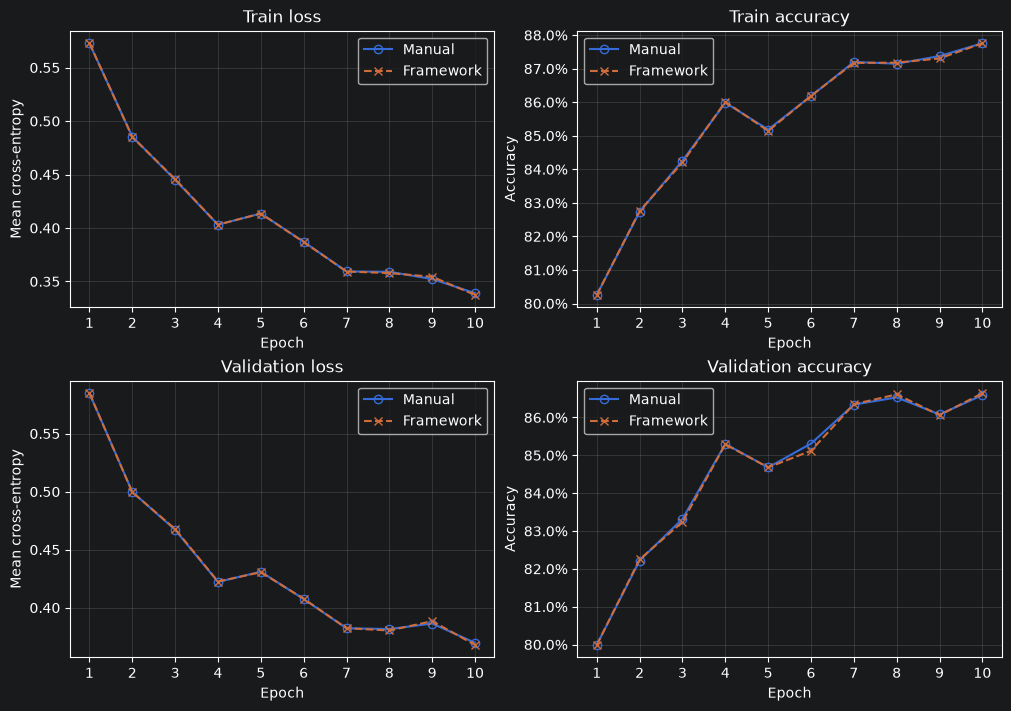

In [56]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

manual_plot = torch.tensor(mlp_history, dtype=torch.float64).numpy()
framework_plot = torch.tensor(
    framework_mlp_history, dtype=torch.float64,
).numpy()

epochs = range(1, len(mlp_history) + 1)
titles = [
    "Train loss", "Train accuracy",
    "Validation loss", "Validation accuracy",
]

fig, axes = plt.subplots(
    2, 2, figsize=(10, 7), constrained_layout=True,
)

for i, (ax, title) in enumerate(zip(axes.flat, titles)):
    ax.plot(
        epochs, manual_plot[:, i], "-o",
        markerfacecolor="none", label="Manual",
    )
    ax.plot(
        epochs, framework_plot[:, i], "--x",
        label="Framework",
    )
    ax.set(title=title, xlabel="Epoch")
    ax.set_xticks(epochs)
    ax.grid(alpha=0.25)
    ax.legend()

    if i in (1, 3):
        ax.set_ylabel("Accuracy")
        ax.yaxis.set_major_formatter(PercentFormatter(1))
    else:
        ax.set_ylabel("Mean cross-entropy")

plt.show()